# Fase 3: exploración

**analisis-barberias-peluquerias** · barberías de Santiago en Instagram

Antes de entrenar un modelo hay que saber dónde hay señal. Este notebook responde cinco preguntas:

1. ¿Cómo se distribuyen los likes y qué pasa con los posts virales?
2. ¿Cuánto depende el rendimiento de la cuenta, y en particular de su tamaño?
3. Dentro de una misma cuenta, ¿rinden más los reels, los carruseles, las preguntas, los llamados a la acción?
4. ¿Importan el día y la hora?
5. ¿Qué variables numéricas aportan y cuáles están correlacionadas entre sí?

Lee `data/posts_features.csv`, generado por `preparar_features.py` en la Fase 2.

Con `ANONIMIZAR = True` (primera celda de código) las cuentas aparecen como "Barbería 01" a "Barbería 19", numeradas de la
que tiene más posts a la que tiene menos, y no se muestran los textos de los posts. Son los mismos códigos de los otros
notebooks y del dashboard.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from anonimizar import mapa_cuentas

posts = pd.read_csv(RAIZ / "data" / "posts_features.csv", encoding="utf-8-sig",
                    dtype={"post_id": str}, parse_dates=["fecha_publicacion_utc", "fecha_local"])

# True: cuentas como "Barbería 01..19" y sin textos de los posts. Déjalo así si vas a publicar el notebook.
ANONIMIZAR = True
if ANONIMIZAR:
    posts["username"] = posts["username"].map(mapa_cuentas(posts["username"]))

GUARDAR_FIGURAS = True      # copia algunos gráficos en docs/img/ para el README
CARPETA_FIGURAS = RAIZ / "docs" / "img"


def guardar(fig, nombre):
    if GUARDAR_FIGURAS:
        CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
        fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

# Estilo de los gráficos: una serie en azul, lo secundario en gris, grilla y ejes discretos
AZUL, GRIS = "#2a78d6", "#8a8984"
TINTA, TINTA_2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO, "figure.dpi": 110,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 1, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def pct(log_dif):
    # Diferencia en escala log -> diferencia porcentual en likes
    return (np.exp(log_dif) - 1) * 100


print(f"{len(posts):,} posts de {posts['username'].nunique()} cuentas, "
      f"del {posts['fecha_local'].min():%d-%m-%Y} al {posts['fecha_local'].max():%d-%m-%Y}")

1,292 posts de 19 cuentas, del 15-10-2025 al 07-10-2026


## 1. Vista general

Primero, cuántos posts aporta cada cuenta. Si unas pocas concentran los datos, el modelo aprendería sobre todo de ellas;
para eso la Fase 2 calculó `peso_cuenta`.

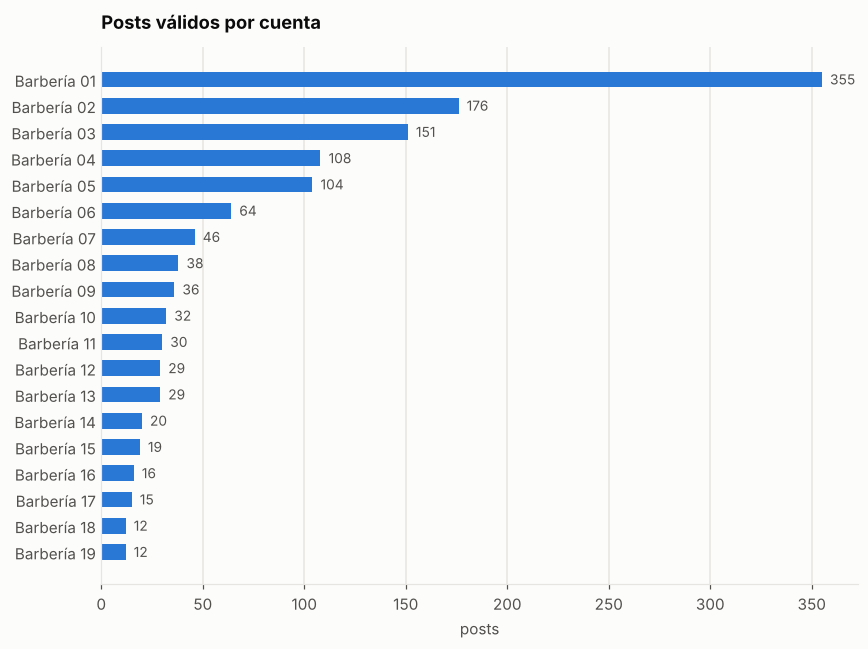

Las 3 cuentas con más posts (Barbería 01, Barbería 02, Barbería 03) suman el 53% del total.


In [2]:
por_cuenta = posts.groupby("username").agg(
    posts=("post_id", "size"), seguidores=("seguidores", "first"),
    mediana_likes=("likes", "median"), pct_reels=("formato", lambda s: (s == "reel").mean() * 100),
).sort_values("posts")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(por_cuenta.index, por_cuenta["posts"], height=0.6, color=AZUL)
for y, v in enumerate(por_cuenta["posts"]):
    ax.text(v + 4, y, f"{v}", va="center", fontsize=9, color=TINTA_2)
ax.set_title("Posts válidos por cuenta")
ax.set_xlabel("posts")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

top3 = por_cuenta["posts"].nlargest(3)
print(f"Las 3 cuentas con más posts ({', '.join(top3.index)}) suman el {top3.sum() / len(posts):.0%} del total.")

## 2. Distribución de likes

Los likes de Instagram suelen tener una cola muy larga: la mayoría de los posts tiene pocos y unos pocos tienen muchísimos.
Por eso el target del modelo es `log_likes` = ln(1 + likes).

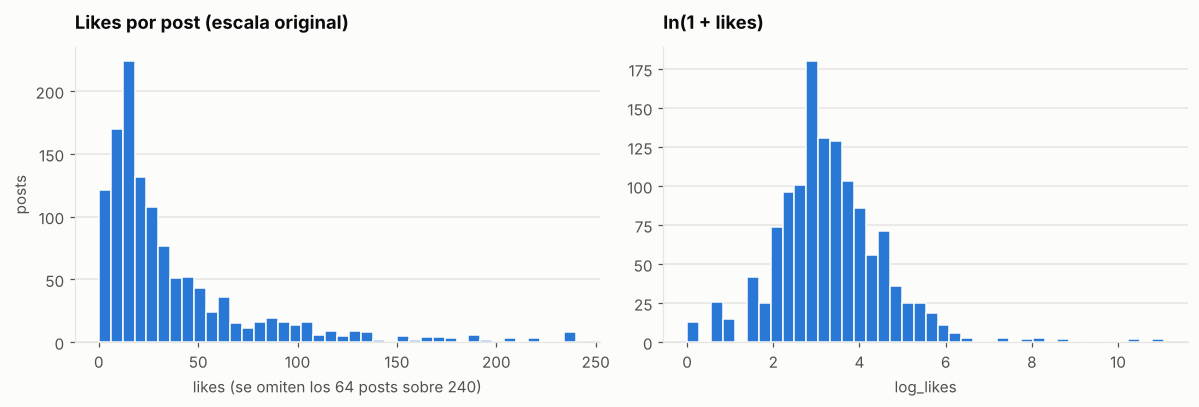

Mediana: 23 likes | promedio: 288 | máximo: 64,219
El 1% de los posts con más likes (13 posts) concentra el 80% de todos los likes.
Asimetría: 15.9 en escala original vs 1.16 en log.


In [3]:
corte = posts["likes"].quantile(0.95)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

ax1.hist(posts.loc[posts["likes"] <= corte, "likes"], bins=40, color=AZUL, edgecolor=FONDO, linewidth=1)
ax1.set_title("Likes por post (escala original)")
ax1.set_xlabel(f"likes (se omiten los {(posts['likes'] > corte).sum()} posts sobre {corte:.0f})")
ax1.set_ylabel("posts")

ax2.hist(posts["log_likes"], bins=40, color=AZUL, edgecolor=FONDO, linewidth=1)
ax2.set_title("ln(1 + likes)")
ax2.set_xlabel("log_likes")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar(fig, "distribucion_likes")
plt.show()

top1 = posts["likes"] >= posts["likes"].quantile(0.99)
print(f"Mediana: {posts['likes'].median():.0f} likes | promedio: {posts['likes'].mean():.0f} | máximo: {posts['likes'].max():,}")
print(f"El 1% de los posts con más likes ({top1.sum()} posts) concentra el {posts.loc[top1, 'likes'].sum() / posts['likes'].sum():.0%} de todos los likes.")
print(f"Asimetría: {posts['likes'].skew():.1f} en escala original vs {posts['log_likes'].skew():.2f} en log.")

### Los virales

Un post es atípico para su cuenta si su `log_likes` se aleja mucho de lo normal en esa cuenta. Se usa un z robusto
(mediana y desviación absoluta mediana), porque un promedio se dejaría arrastrar por los mismos virales.

In [4]:
def z_robusto(s):
    mad = 1.4826 * (s - s.median()).abs().median()
    return (s - s.median()) / mad if mad > 0 else s * 0

posts["z_cuenta"] = posts.groupby("username")["log_likes"].transform(z_robusto)
virales = posts[posts["z_cuenta"] > 3.5].sort_values("likes", ascending=False)
print(f"{len(virales)} posts con z robusto > 3,5 dentro de su cuenta")

columnas = ["username", "fecha", "formato", "likes", "comentarios", "seguidores"] + ([] if ANONIMIZAR else ["texto"])
(virales.head(12)
 .assign(fecha=lambda d: d["fecha_local"].dt.strftime("%d-%m-%Y"),
         texto=lambda d: d["texto_propio"].fillna("").str.replace("\n", " ").str.slice(0, 60))
 [columnas])

25 posts con z robusto > 3,5 dentro de su cuenta


,username,fecha,formato,likes,comentarios,seguidores
883,Barbería 01,30-06-2026,reel,64219,140,8693
463,Barbería 02,10-11-2025,reel,54018,983,10225
462,Barbería 02,09-11-2025,carrusel,44337,490,10225
1070,Barbería 03,04-04-2026,reel,36770,939,12268
1114,Barbería 03,28-06-2026,reel,33385,1185,12268
466,Barbería 02,12-11-2025,reel,23031,67,10225
1101,Barbería 03,05-06-2026,reel,13356,1331,12268
1125,Barbería 03,22-07-2026,reel,8273,417,12268
488,Barbería 02,03-01-2026,reel,5656,43,10225
467,Barbería 02,14-11-2025,reel,5652,69,10225


Los posts más virales no son cortes de pelo: son **humor y contingencia**. El caso más claro es la serie de una de las barberías
con "cortes de los candidatos" en noviembre de 2025, en plena elección presidencial, que llegó a 54 mil likes en una cuenta
de 10 mil seguidores. Ninguna feature del dataset (formato, hora, largo del texto) captura eso, así que el modelo no va
a poder predecir estos picos. Se dejan en los datos, porque son reales, pero en la Fase 4 conviene medir el error con y
sin ellos.

## 3. ¿Cuánto pesa la cuenta?

Si la cuenta explica la mayor parte de la variación, las features del post tienen poco espacio para aportar.

In [5]:
media_cuenta = posts.groupby("username")["log_likes"].transform("mean")
var_total = posts["log_likes"].var(ddof=0)
var_dentro = (posts["log_likes"] - media_cuenta).var(ddof=0)
print(f"La cuenta explica el {1 - var_dentro / var_total:.0%} de la variación de log_likes.")
print(f"El {var_dentro / var_total:.0%} restante es variación entre posts de una misma cuenta.")

La cuenta explica el 41% de la variación de log_likes.
El 59% restante es variación entre posts de una misma cuenta.


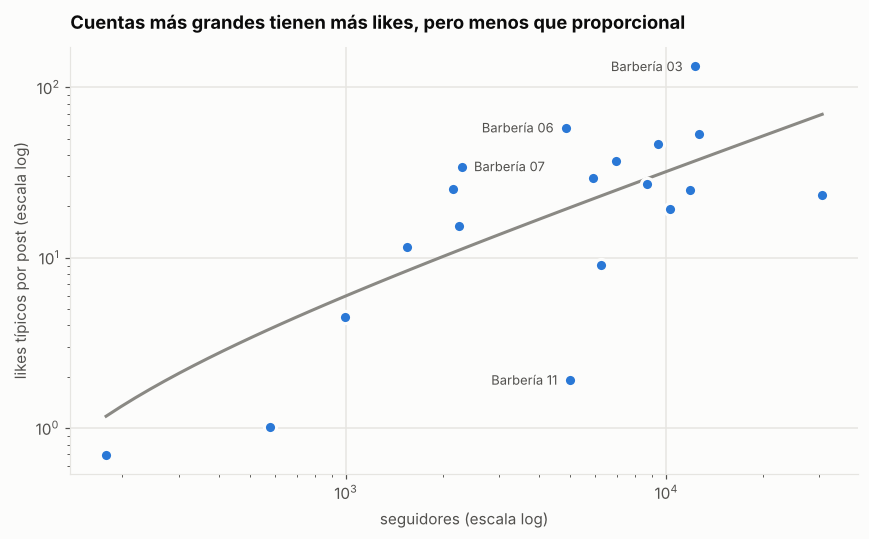

Correlación entre log(seguidores) y log_likes promedio de la cuenta: 0.72 (19 cuentas)
Pendiente: 0.68 → el doble de seguidores se asocia a 1.60 veces los likes (+60%), no al doble.


In [6]:
nivel = posts.groupby("username").agg(seguidores=("seguidores", "first"), log_likes=("log_likes", "mean"))
nivel["likes_tipicos"] = np.exp(nivel["log_likes"]) - 1           # media geométrica de likes
pendiente, intercepto = np.polyfit(np.log(nivel["seguidores"]), nivel["log_likes"], 1)
r = np.corrcoef(np.log(nivel["seguidores"]), nivel["log_likes"])[0, 1]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.linspace(np.log(nivel["seguidores"].min()), np.log(nivel["seguidores"].max()), 50)
ax.plot(np.exp(x), np.exp(intercepto + pendiente * x) - 1, color=GRIS, linewidth=2, zorder=1)
ax.scatter(nivel["seguidores"], nivel["likes_tipicos"], s=64, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=2)
# se etiquetan las 4 cuentas más alejadas de la tendencia
residuo = nivel["log_likes"] - (intercepto + pendiente * np.log(nivel["seguidores"]))
mitad = np.log(nivel["seguidores"]).mean()
for usuario in residuo.abs().nlargest(4).index:
    fila = nivel.loc[usuario]
    derecha = np.log(fila["seguidores"]) < mitad
    ax.annotate(usuario, (fila["seguidores"], fila["likes_tipicos"]), xytext=(8 if derecha else -8, -3),
                ha="left" if derecha else "right", textcoords="offset points", fontsize=8.5, color=TINTA_2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Cuentas más grandes tienen más likes, pero menos que proporcional")
ax.set_xlabel("seguidores (escala log)")
ax.set_ylabel("likes típicos por post (escala log)")
plt.tight_layout()
guardar(fig, "likes_vs_seguidores")
plt.show()

print(f"Correlación entre log(seguidores) y log_likes promedio de la cuenta: {r:.2f} ({len(nivel)} cuentas)")
print(f"Pendiente: {pendiente:.2f} → el doble de seguidores se asocia a {2 ** pendiente:.2f} veces los likes "
      f"({(2 ** pendiente - 1) * 100:+.0f}%), no al doble.")

El tamaño explica buena parte, pero no todo: hay cuentas con muchos seguidores y pocos likes, y al revés. Ese "estilo"
propio de cada cuenta (comunidad, tipo de contenido, si los seguidores son reales) es información que el modelo necesita.
En la Fase 4 se incluye como el **promedio de log_likes de la cuenta calculado solo con los datos de entrenamiento**.

## 4. Efectos dentro de cada cuenta

Comparar todos los reels contra todas las imágenes mezcla dos cosas: el formato y la cuenta. Si las cuentas grandes
publican más reels, los reels parecerían mejores aunque el formato no influya en nada.

Para aislar el efecto, la comparación se hace **dentro de cada cuenta**: para cada una se calcula la diferencia de
log_likes promedio entre los dos grupos (si tiene al menos 3 posts en cada uno), y luego se resume:

- **a favor**: en cuántas cuentas el grupo A rinde más que el B,
- **mediana y media** de esas diferencias, convertidas a %,
- **IC 90%**: intervalo de confianza de la media, por bootstrap de cuentas (se remuestrean cuentas, no posts, porque
  los posts de una misma cuenta no son independientes). Si el intervalo no cruza el 0, la señal es clara.

In [7]:
rng = np.random.default_rng(42)


def efecto_dentro_de_cuentas(mask_a, mask_b, min_posts=3, n_boot=4000):
    difs = {}
    for usuario, g in posts.groupby("username"):
        a = g.loc[mask_a.loc[g.index], "log_likes"]
        b = g.loc[mask_b.loc[g.index], "log_likes"]
        if len(a) >= min_posts and len(b) >= min_posts:
            difs[usuario] = a.mean() - b.mean()
    d = pd.Series(difs, dtype=float)
    medias = rng.choice(d.to_numpy(), size=(n_boot, len(d)), replace=True).mean(axis=1)
    bajo, alto = np.percentile(medias, [5, 95])
    return pd.Series({"cuentas": len(d), "a_favor": int((d > 0).sum()), "mediana_%": pct(d.median()),
                      "media_%": pct(d.mean()), "ic90_bajo_%": pct(bajo), "ic90_alto_%": pct(alto)})


mediana_largo = posts.groupby("username")["largo_texto_propio"].transform("median")
comparaciones = {
    "Reel vs no reel": (posts["formato"] == "reel", posts["formato"] != "reel"),
    "Carrusel vs imagen": (posts["formato"] == "carrusel", posts["formato"] == "imagen"),
    "Con llamado a la acción vs sin": (posts["tiene_llamado_accion"], ~posts["tiene_llamado_accion"]),
    "Con pregunta vs sin": (posts["tiene_pregunta"], ~posts["tiene_pregunta"]),
    "Fin de semana vs lunes a viernes": (posts["es_fin_de_semana"], ~posts["es_fin_de_semana"]),
    "Tarde (12-18 h) vs mañana (6-12 h)": (posts["franja"] == "tarde", posts["franja"] == "manana"),
    "Noche (18-24 h) vs tarde": (posts["franja"] == "noche", posts["franja"] == "tarde"),
    "Texto más largo que lo habitual vs más corto": (posts["largo_texto_propio"] > mediana_largo,
                                                     posts["largo_texto_propio"] <= mediana_largo),
}
efectos = pd.DataFrame({k: efecto_dentro_de_cuentas(a, b) for k, (a, b) in comparaciones.items()}).T
efectos[["cuentas", "a_favor"]] = efectos[["cuentas", "a_favor"]].astype(int)
efectos["señal"] = np.where((efectos["ic90_bajo_%"] > 0) | (efectos["ic90_alto_%"] < 0), "clara", "no concluyente")
efectos.round(0)

,cuentas,a_favor,mediana_%,media_%,ic90_bajo_%,ic90_alto_%,señal
Reel vs no reel,13,9,39.0,18.0,-12.0,52.0,no concluyente
Carrusel vs imagen,7,6,61.0,62.0,28.0,107.0,clara
Con llamado a la acción vs sin,16,6,-25.0,-23.0,-35.0,-10.0,clara
Con pregunta vs sin,13,7,1.0,-1.0,-13.0,13.0,no concluyente
Fin de semana vs lunes a viernes,14,8,12.0,9.0,-5.0,25.0,no concluyente
Tarde (12-18 h) vs mañana (6-12 h),16,10,15.0,11.0,-4.0,29.0,no concluyente
Noche (18-24 h) vs tarde,17,7,-6.0,-2.0,-13.0,11.0,no concluyente
Texto más largo que lo habitual vs más corto,19,11,4.0,2.0,-8.0,14.0,no concluyente


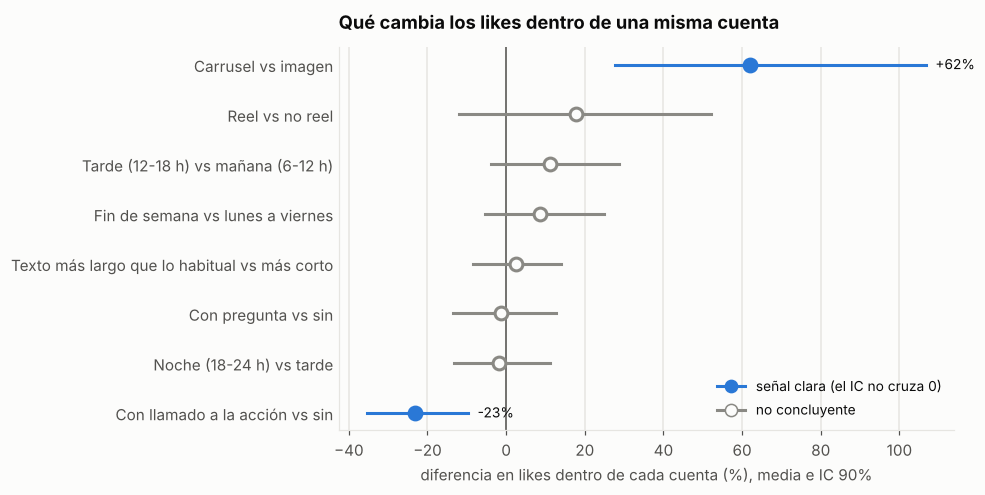

In [8]:
orden = efectos.sort_values("media_%")
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axvline(0, color=TINTA_2, linewidth=1, zorder=1)
for y, (nombre, fila) in enumerate(orden.iterrows()):
    clara = fila["señal"] == "clara"
    color = AZUL if clara else GRIS
    ax.plot([fila["ic90_bajo_%"], fila["ic90_alto_%"]], [y, y], color=color, linewidth=2, zorder=2)
    ax.scatter(fila["media_%"], y, s=70, zorder=3, color=color if clara else FONDO, edgecolor=color, linewidth=2)
    if clara:
        ax.annotate(f"{fila['media_%']:+.0f}%", (fila["ic90_alto_%"], y), xytext=(6, -3),
                    textcoords="offset points", fontsize=9, color=TINTA)
ax.set_yticks(range(len(orden)), orden.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("diferencia en likes dentro de cada cuenta (%), media e IC 90%")
ax.set_title("Qué cambia los likes dentro de una misma cuenta")
ax.legend(handles=[
    Line2D([], [], marker="o", color=AZUL, markerfacecolor=AZUL, markersize=8, linewidth=2, label="señal clara (el IC no cruza 0)"),
    Line2D([], [], marker="o", color=GRIS, markerfacecolor=FONDO, markersize=8, linewidth=2, label="no concluyente"),
], loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

Detalle por cuenta de las dos comparaciones de formato, para ver si el resultado depende de una sola cuenta:

In [9]:
def difs_por_cuenta(mask_a, mask_b, min_posts=3):
    filas = []
    for usuario, g in posts.groupby("username"):
        a = g.loc[mask_a.loc[g.index], "log_likes"]
        b = g.loc[mask_b.loc[g.index], "log_likes"]
        if len(a) >= min_posts and len(b) >= min_posts:
            filas.append({"cuenta": usuario, "posts_A": len(a), "posts_B": len(b), "diferencia_%": pct(a.mean() - b.mean())})
    return pd.DataFrame(filas).sort_values("diferencia_%", ascending=False).round(0)


print("Reel (A) vs no reel (B)")
display(difs_por_cuenta(*comparaciones["Reel vs no reel"]))
print("Carrusel (A) vs imagen (B)")
display(difs_por_cuenta(*comparaciones["Carrusel vs imagen"]))

Reel (A) vs no reel (B)


,cuenta,posts_A,posts_B,diferencia_%
2,Barbería 03,115,36,132.0
7,Barbería 11,4,26,117.0
4,Barbería 05,48,56,93.0
3,Barbería 04,28,80,70.0
8,Barbería 12,22,7,66.0
9,Barbería 13,23,6,59.0
1,Barbería 02,89,87,39.0
6,Barbería 10,15,17,30.0
5,Barbería 06,60,4,7.0
12,Barbería 16,12,4,-7.0


Carrusel (A) vs imagen (B)


,cuenta,posts_A,posts_B,diferencia_%
0,Barbería 02,26,61,234.0
5,Barbería 10,14,3,116.0
6,Barbería 11,10,16,64.0
3,Barbería 05,16,40,61.0
2,Barbería 04,75,5,52.0
4,Barbería 09,23,11,14.0
1,Barbería 03,24,12,-12.0


## 5. Día y hora

¿A qué hora publican las barberías, y rinde más alguna franja o día? El efecto de cada categoría se mide contra el promedio
de su propia cuenta, con el mismo bootstrap de cuentas.

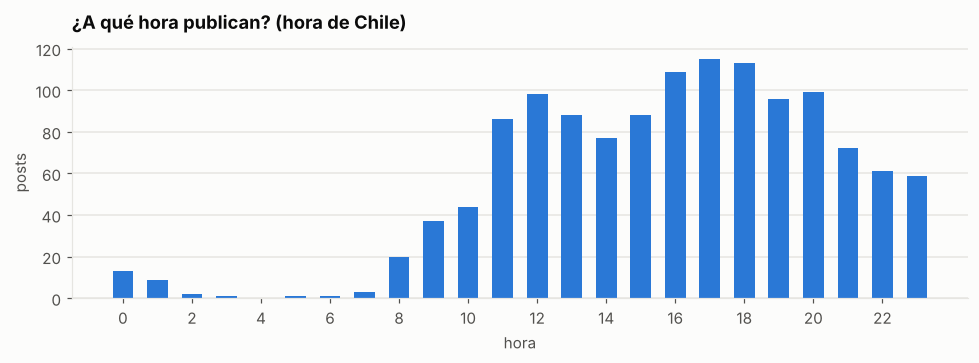

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
por_hora = posts["hora_local"].value_counts().reindex(range(24), fill_value=0)
ax.bar(por_hora.index, por_hora.values, width=0.6, color=AZUL)
ax.set_title("¿A qué hora publican? (hora de Chile)")
ax.set_xlabel("hora")
ax.set_ylabel("posts")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

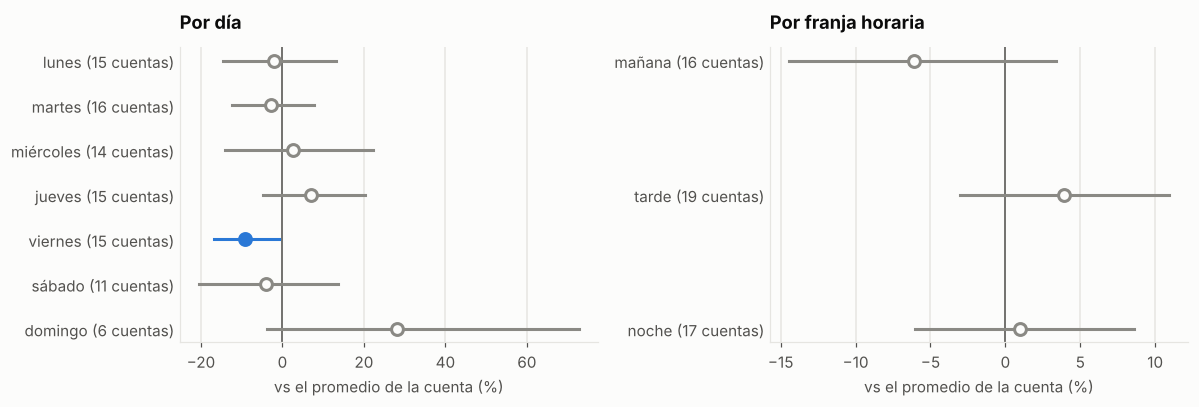

cuentas  efecto_%  ic90_bajo_%  ic90_alto_%
día    lunes         15.0      -2.0        -15.0         13.0
       martes        16.0      -3.0        -12.0          8.0
       miércoles     14.0       2.0        -14.0         22.0
       jueves        15.0       7.0         -5.0         20.0
       viernes       15.0      -9.0        -17.0         -1.0
       sábado        11.0      -4.0        -21.0         14.0
       domingo        6.0      28.0         -4.0         73.0
franja mañana        16.0      -6.0        -14.0          3.0
       tarde         19.0       4.0         -3.0         11.0
       noche         17.0       1.0         -6.0          9.0

In [11]:
posts["resid_cuenta"] = posts["log_likes"] - media_cuenta


def efecto_por_categoria(columna, orden, min_posts=3, min_cuentas=5, n_boot=4000):
    tabla = (posts.groupby(["username", columna])["resid_cuenta"].agg(["mean", "size"])
             .query("size >= @min_posts")["mean"].unstack(columna).reindex(columns=orden))
    filas = {}
    for cat in orden:
        valores = tabla[cat].dropna().to_numpy()
        if len(valores) < min_cuentas:      # muy pocas cuentas para estimar algo
            continue
        medias = rng.choice(valores, size=(n_boot, len(valores)), replace=True).mean(axis=1)
        filas[cat] = {"cuentas": len(valores), "efecto_%": pct(valores.mean()),
                      "ic90_bajo_%": pct(np.percentile(medias, 5)), "ic90_alto_%": pct(np.percentile(medias, 95))}
    return pd.DataFrame(filas).T


dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
franjas = ["madrugada", "manana", "tarde", "noche"]
por_dia = efecto_por_categoria("nombre_dia", dias)
por_franja = efecto_por_categoria("franja", franjas).rename(index={"manana": "mañana"})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tabla, titulo in [(axes[0], por_dia, "Por día"), (axes[1], por_franja, "Por franja horaria")]:
    ax.axvline(0, color=TINTA_2, linewidth=1)
    for y, (cat, fila) in enumerate(tabla.iloc[::-1].iterrows()):
        clara = fila["ic90_bajo_%"] > 0 or fila["ic90_alto_%"] < 0
        color = AZUL if clara else GRIS
        ax.plot([fila["ic90_bajo_%"], fila["ic90_alto_%"]], [y, y], color=color, linewidth=2)
        ax.scatter(fila["efecto_%"], y, s=60, color=color if clara else FONDO, edgecolor=color, linewidth=2, zorder=3)
    ax.set_yticks(range(len(tabla)), [f"{c} ({int(n)} cuentas)" for c, n in tabla["cuentas"].iloc[::-1].items()])
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
    ax.set_xlabel("vs el promedio de la cuenta (%)")
plt.tight_layout()
plt.show()
pd.concat({"día": por_dia, "franja": por_franja}).round(0)

Las categorías con menos de 5 cuentas (por ejemplo, la madrugada) quedan fuera porque no alcanzan para estimar nada.

**Cuidado con las comparaciones múltiples.** Aquí se miran 10 categorías a la vez con intervalos de 90%. Aunque el día no
influyera en nada, lo esperable es que alrededor de 1 de cada 10 intervalos quede lejos del 0 solo por azar. Que una
categoría aislada aparezca marcada, sin un patrón coherente alrededor (por ejemplo, el viernes peor pero el jueves y el
sábado normales), no es evidencia suficiente. La lectura honesta es que **no hay un efecto claro del día ni de la franja**.

## 6. Variables numéricas

Correlación de Spearman entre cada variable y los likes, calculada **dentro de cada cuenta** (cuentas con al menos 10
posts y variación en la variable). Se informa la mediana entre cuentas y en cuántas la relación es positiva.

`log_comentarios` aparece como referencia: está muy correlacionada con los likes, pero **no se puede usar como feature**
porque los comentarios se conocen después de publicar. Lo mismo vale para `engagement_rate`.

In [12]:
def spearman(x, y):
    return x.rank().corr(y.rank())


variables = ["largo_texto_propio", "palabras_texto_propio", "hashtags_propios", "hashtags_total", "emojis_propios",
             "posts_ultimos_7_dias", "dias_desde_post_anterior", "hora_local", "edad_dias_captura", "log_comentarios"]
filas = []
for v in variables:
    rhos = []
    for _, g in posts.groupby("username"):
        g = g[[v, "log_likes"]].dropna()
        if len(g) >= 10 and g[v].nunique() > 2:
            rhos.append(spearman(g[v], g["log_likes"]))
    rhos = pd.Series(rhos).dropna()
    filas.append({"variable": v, "cuentas": len(rhos), "positiva_en": int((rhos > 0).sum()),
                  "rho_mediana": rhos.median(), "rho_min": rhos.min(), "rho_max": rhos.max()})
pd.DataFrame(filas).set_index("variable").round(2)

,cuentas,positiva_en,rho_mediana,rho_min,rho_max
variable,,,,,
largo_texto_propio,19,11,0.07,-0.63,0.45
palabras_texto_propio,19,12,0.07,-0.59,0.46
hashtags_propios,17,11,0.05,-0.45,0.31
hashtags_total,18,10,0.01,-0.45,0.31
emojis_propios,18,11,0.09,-0.58,0.57
posts_ultimos_7_dias,18,9,0.02,-0.50,0.29
dias_desde_post_anterior,19,12,0.05,-0.60,0.58
hora_local,19,10,0.01,-0.25,0.61
edad_dias_captura,19,6,-0.04,-0.76,0.50


Todas las correlaciones son débiles (mediana entre cuentas por debajo de 0,1) y cambian mucho de una cuenta a otra. Las de
texto apuntan levemente a que los posts con más texto y más emojis de lo habitual en la cuenta rinden un poco más, pero
es una señal débil.

La edad del post al leer sus likes tampoco muestra relación (mediana −0,04). Si algo, los posts más antiguos tienen
levemente menos likes, lo que calza con cuentas que han ido creciendo. No hay señal de que los posts más nuevos estén
"incompletos", así que el corte de 7 días de la Fase 2 es suficiente.

### Correlación entre las features

Dos features muy correlacionadas entre sí aportan casi la misma información y vuelven inestables los coeficientes de
una regresión lineal. Conviene quedarse con una de cada par.

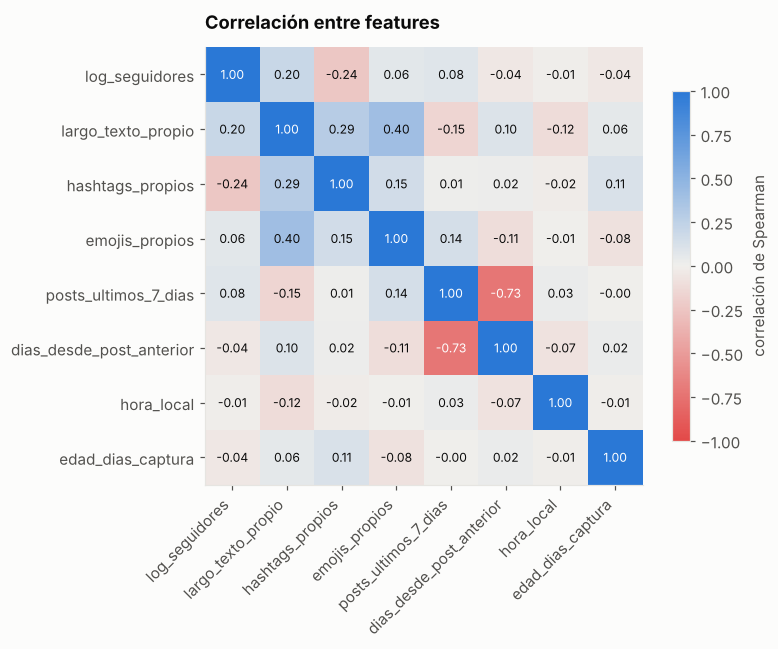

Pares con |correlación| >= 0,5:
posts_ultimos_7_dias  dias_desde_post_anterior   -0.73


In [13]:
candidatas = ["log_seguidores", "largo_texto_propio", "hashtags_propios", "emojis_propios", "posts_ultimos_7_dias",
              "dias_desde_post_anterior", "hora_local", "edad_dias_captura"]
corr = posts[candidatas].rank().corr()

cmap = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(candidatas)), candidatas, rotation=45, ha="right")
ax.set_yticks(range(len(candidatas)), candidatas)
ax.grid(False)
for i in range(len(candidatas)):
    for j in range(len(candidatas)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valor) > 0.6 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlación de Spearman")
ax.set_title("Correlación entre features")
plt.tight_layout()
plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s.abs() >= 0.5].sort_values(key=abs, ascending=False))
print("Pares con |correlación| >= 0,5:")
print(pares.round(2).to_string() if len(pares) else "  ninguno")

## 7. Conclusiones

*Números de la corrida del 14-10-2026 (19 cuentas, 1.292 posts). Si vuelves a extraer, cambian un poco; las celdas de
arriba siempre muestran los valores actuales.*

1. **Los likes están extremadamente concentrados.** La mediana es de 23 likes, pero el 1% de los posts (13) concentra el
   80% de todos los likes. Los grandes virales son humor y contingencia, como una serie de "cortes" de los candidatos
   presidenciales, algo que ninguna feature captura. El target tiene que ser `log_likes`, y el error se
   mide en esa escala.

2. **La cuenta explica cerca del 41% de la variación.** El tamaño importa (correlación de 0,72 entre seguidores y likes
   típicos), pero menos que proporcionalmente: el doble de seguidores se asocia a cerca de un 60% más de likes, no al
   doble. Además, cuentas de tamaño parecido rinden muy distinto (una tiene 30 mil seguidores y una mediana de 24
   likes; otra, con 12 mil, tiene 124). El modelo necesita una variable con el nivel propio de cada cuenta.

3. **Dentro de cada cuenta hay dos señales claras.**
   - **Los carruseles rinden más que las imágenes** sueltas: alrededor de +60%, en 6 de las 7 cuentas que usan ambos.
   - **Los posts con llamado a la acción** (agenda tu hora, reserva, WhatsApp) **rinden menos**: alrededor de −25%, en 10
     de 16 cuentas. Los posts promocionales reciben menos likes que los de contenido.

4. **Los reels apuntan a rendir más, pero no es concluyente.** La mediana por cuenta es de +39% (9 de 13 cuentas a favor),
   pero el intervalo cruza el 0. Barbería 01, la que más publica y casi solo con reels, va en contra y pesa mucho.

5. **No hay señal en el día, la hora, las preguntas ni el ritmo de publicación.** La tarde rinde un poco más que la
   mañana y el viernes un poco menos, pero ninguno es concluyente considerando cuántas comparaciones se hicieron. El largo
   del texto, los emojis y los hashtags propios tienen correlaciones débiles (0,05 a 0,1). La expectativa realista para
   el modelo: la mayor parte de lo que se puede predecir viene de la cuenta, y las features del post suman poco.

### Decisiones para la Fase 4

| Tema | Decisión |
|---|---|
| Target | `log_likes`; métrica principal: MAE en escala log, también expresada en % |
| Nivel de la cuenta | promedio de `log_likes` de la cuenta, calculado **solo con el conjunto de entrenamiento** |
| Features del post | `formato` (one-hot), `tiene_llamado_accion`, `menciona_precio_promo`, `tiene_pregunta`, `franja`, `es_fin_de_semana`, `largo_texto_propio` (en log), `hashtags_propios`, `emojis_propios`, `posts_ultimos_7_dias`, `log_seguidores` |
| Se descarta | `dias_desde_post_anterior` (muy correlacionada con `posts_ultimos_7_dias`) |
| No se puede usar | `comentarios`, `log_comentarios`, `engagement_rate` (se conocen después de publicar) |
| Control | `edad_dias_captura` no influye; queda fuera del modelo |
| Virales | se mantienen; el error se reporta con y sin los posts de z > 3,5 |
| Pesos | `peso_cuenta` como `sample_weight` (la Fase 4 mostró que no mejora: el modelo final va sin pesos) |
| Validación | split temporal y `GroupKFold` por cuenta |